In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import sklearn.metrics as metrics
from sklearn.metrics import mean_squared_error, r2_score


1. machine learning의 의미
- machine : 기계가
- learning : 배운다\
→ 데이터로부터 특징, 패턴들을 찾아내는 법을 컴퓨터가 배운다

2. 어떻게 배울까?\
우리가 시험공부를 할 때, 문제가 주어지면 정답을 최대한 잘 맞추도록 공부한다.\
컴퓨터도 마찬가지로 문제(데이터)가 주어지면, 특징과 패턴을 찾아 정답(예측값)을 최대한 잘 맞추도록 학습한다.

- 문제 : input 값, 독립변수(X)
- 정답 : output 값, 예측값, 종속변수(Y)

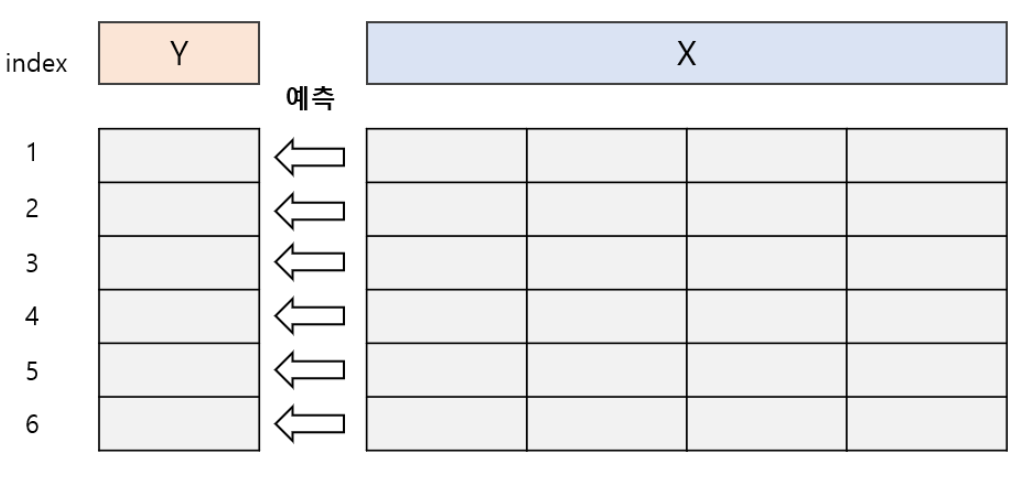

**예측값인 Y를 최대한 정확하게 맞추면 잘 배운 것이다**

3. 학습 규칙\
우리는 학창시절 문제집으로 시험공부를 하고, 시험으로 정답을 얼마나 잘 맞추는지 평가받는다.\
문제집은 문제와 정답을 모두 알고있으며, 이 둘을 맞추어 가며 공부한다.\
시험문제는 당일날 문제만 알고, 정답을 모른다. 시험 후 채점을 통해 최종 점수가 결정된다.

**머신러닝 학습도 마찬가지이다**
- 문제집 : train_set, 실제 학습 시 사용하는 독립변수(X)-종속변수(Y)가 매칭된 데이터 셋
- 시험문제 : test_set, 머신러닝 학습이 끝난 후 평가에 사용하는 데이터 셋으로, 종속변수 예측값(Y')과 실제 값과의 차이로 성능을 평가


## 8.1 데이터 셋 불러오기

100M 격자 단위로 인구, 용도지역, 도심지(서울시청·강남역)까지의 거리 변수들로부터 119 응급 출동 건수를 예측하는 모형을 만들어보도록 하겠습니다.
- 독립변수(X) : 총 인구, 고령층 인구 비율, 유소년층 인구 비율, 용도지역 별 비율(주, 상, 공), 도심지로부터의 거리
- 종속변수(Y) : 119 응급 출동 건수

머신러닝을 하기 위해서는 데이터를 격자 하나가 한 행, 변수 하나가 한 열인 표 형태로 만들어주어야 합니다. 이 실습에서는 이 형태로 전처리를 마친 데이터를 불러와 사용합니다.

#### 데이터 불러오기

격자 단위 전처리(인구 집계, 용도지역 면적 비율, 도심지까지의 거리, 구급출동 건수 집계)를 마친 데이터를 불러옵니다. 파일은 경위도 좌표계(EPSG:4326)로 저장되어 있으므로, 미터 단위 좌표계(EPSG:5179)로 변환합니다.

In [2]:
pop_grid = gpd.read_file('data/pop_grid_ml.geojson').to_crs(5179)
print(pop_grid.shape)
pop_grid.head(5)

(38094, 11)


,격자고유번호,total_pop,elder_ratio,youth_ratio,industrial_ratio,commercial_ratio,residential_ratio,dist_seoul_city_hall,dist_gangnam_station,emergency_no,geometry
0,다사383536,191.0,0.193717,0.083770,0.0,0.0,0.021743,15668.029228,21940.402533,0.0,"MULTIPOLYGON (((938300 1953600, 938300 1953700..."
1,다사385537,191.0,0.193717,0.083770,0.0,0.0,0.000000,15479.796763,21801.883085,0.0,"MULTIPOLYGON (((938500 1953700, 938500 1953800..."
2,다사386529,319.0,0.147335,0.144201,0.0,0.0,0.195661,15312.335197,21379.365808,2.0,"MULTIPOLYGON (((938600 1952900, 938600 1953000..."
3,다사387525,191.0,0.193717,0.083770,0.0,0.0,1.000000,15193.939852,21130.315213,46.0,"MULTIPOLYGON (((938700 1952500, 938700 1952600..."
4,다사387524,191.0,0.193717,0.083770,0.0,0.0,0.569658,15190.939201,21091.960089,16.0,"MULTIPOLYGON (((938700 1952400, 938700 1952500..."


#### 변수 설명 (코드북)

한 행은 서울시 100m × 100m 격자 하나입니다. 총 38,094개 격자입니다.

| 변수명 | 설명 | 단위·범위 | 역할 | 원자료 |
|---|---|---|---|---|
| `격자고유번호` | 100m 격자 식별 번호 | 문자 | 식별자 | 100M 성별 연령별 거주인구 분포 |
| `total_pop` | 격자 내 총 거주인구 (남녀 0~89세 합계) | 명 | 독립변수(X) | 100M 성별 연령별 거주인구 분포 |
| `elder_ratio` | 고령층 인구 비율 = 65~89세 인구 / 총인구 | 0~1 | 독립변수(X) | 100M 성별 연령별 거주인구 분포 |
| `youth_ratio` | 유소년층 인구 비율 = 0~14세 인구 / 총인구 | 0~1 | 독립변수(X) | 100M 성별 연령별 거주인구 분포 |
| `industrial_ratio` | 격자 면적 중 공업지역 면적 비율 | 0~1 | 독립변수(X) | 용도지역도(국토계획) |
| `commercial_ratio` | 격자 면적 중 상업지역 면적 비율 | 0~1 | 독립변수(X) | 용도지역도(국토계획) |
| `residential_ratio` | 격자 면적 중 주거지역 면적 비율 | 0~1 | 독립변수(X) | 용도지역도(국토계획) |
| `dist_seoul_city_hall` | 격자 중심점에서 서울시청까지의 직선거리 | m | 독립변수(X) | 서울시청 좌표 |
| `dist_gangnam_station` | 격자 중심점에서 강남역까지의 직선거리 | m | 독립변수(X) | 강남역 좌표 |
| `emergency_no` | 2020년 격자 내 119 구급출동 건수 | 건 | 종속변수(Y) | 구급출동 현황 2020 |
| `geometry` | 격자 폴리곤 | EPSG:5179 (불러온 뒤) | 공간 정보 | - |

**전처리 기준**
- 비율 변수는 0~1 값입니다. 0.2는 20%를 뜻합니다.
- 용도지역은 주거·상업·공업지역만 사용했습니다. 용도지역 도형이 겹치는 경우가 있어 각 비율의 최댓값을 1로 제한했습니다.
- 구급출동은 정상 출동만 집계했습니다(오인신고 등 제외). 출동 기록이 없는 격자는 0건으로 처리했습니다.
- 인구가 0명인 격자는 제외했습니다. 이 경우 고령층·유소년층 비율의 분모가 0이라 값을 계산할 수 없기 때문입니다(예: 산, 강). 비율이 0인 격자는 인구는 있지만 해당 연령층이 없는 경우이므로 그대로 두었습니다. 두 경우를 0으로 함께 채우면 의미가 다른 격자가 섞이므로, 계산이 불가능한 격자만 제거했습니다. 이처럼 결측치 처리 방법은 연구자의 판단에 따라 달라질 수 있습니다.

## 8.2 탐색적 데이터 분석 (EDA)

통계모형이나 머신러닝을 돌리기 전, 수집한 데이터를 다각도에서 관찰하고, 직관적으로 이해하는 과정이 꼭 필요합니다!
이를 통해 현상을 더 잘 이해하고, 잠재적인 문제를 발견할 수 있습니다.
이 과정을 EDA(Exploratory Data Analysis)라고 합니다!

- 각 속성의 관측값, 결측값 확인
- 각 속성의 분포, 이상치 확인
- 속성간의 관계를 확인

#### 각 속성의 관측값, 결측값 확인

In [3]:
# 관측값 확인
pop_grid.count()

격자고유번호                  38094
total_pop               38094
elder_ratio             38094
youth_ratio             38094
industrial_ratio        38094
commercial_ratio        38094
residential_ratio       38094
dist_seoul_city_hall    38094
dist_gangnam_station    38094
emergency_no            38094
geometry                38094
dtype: int64

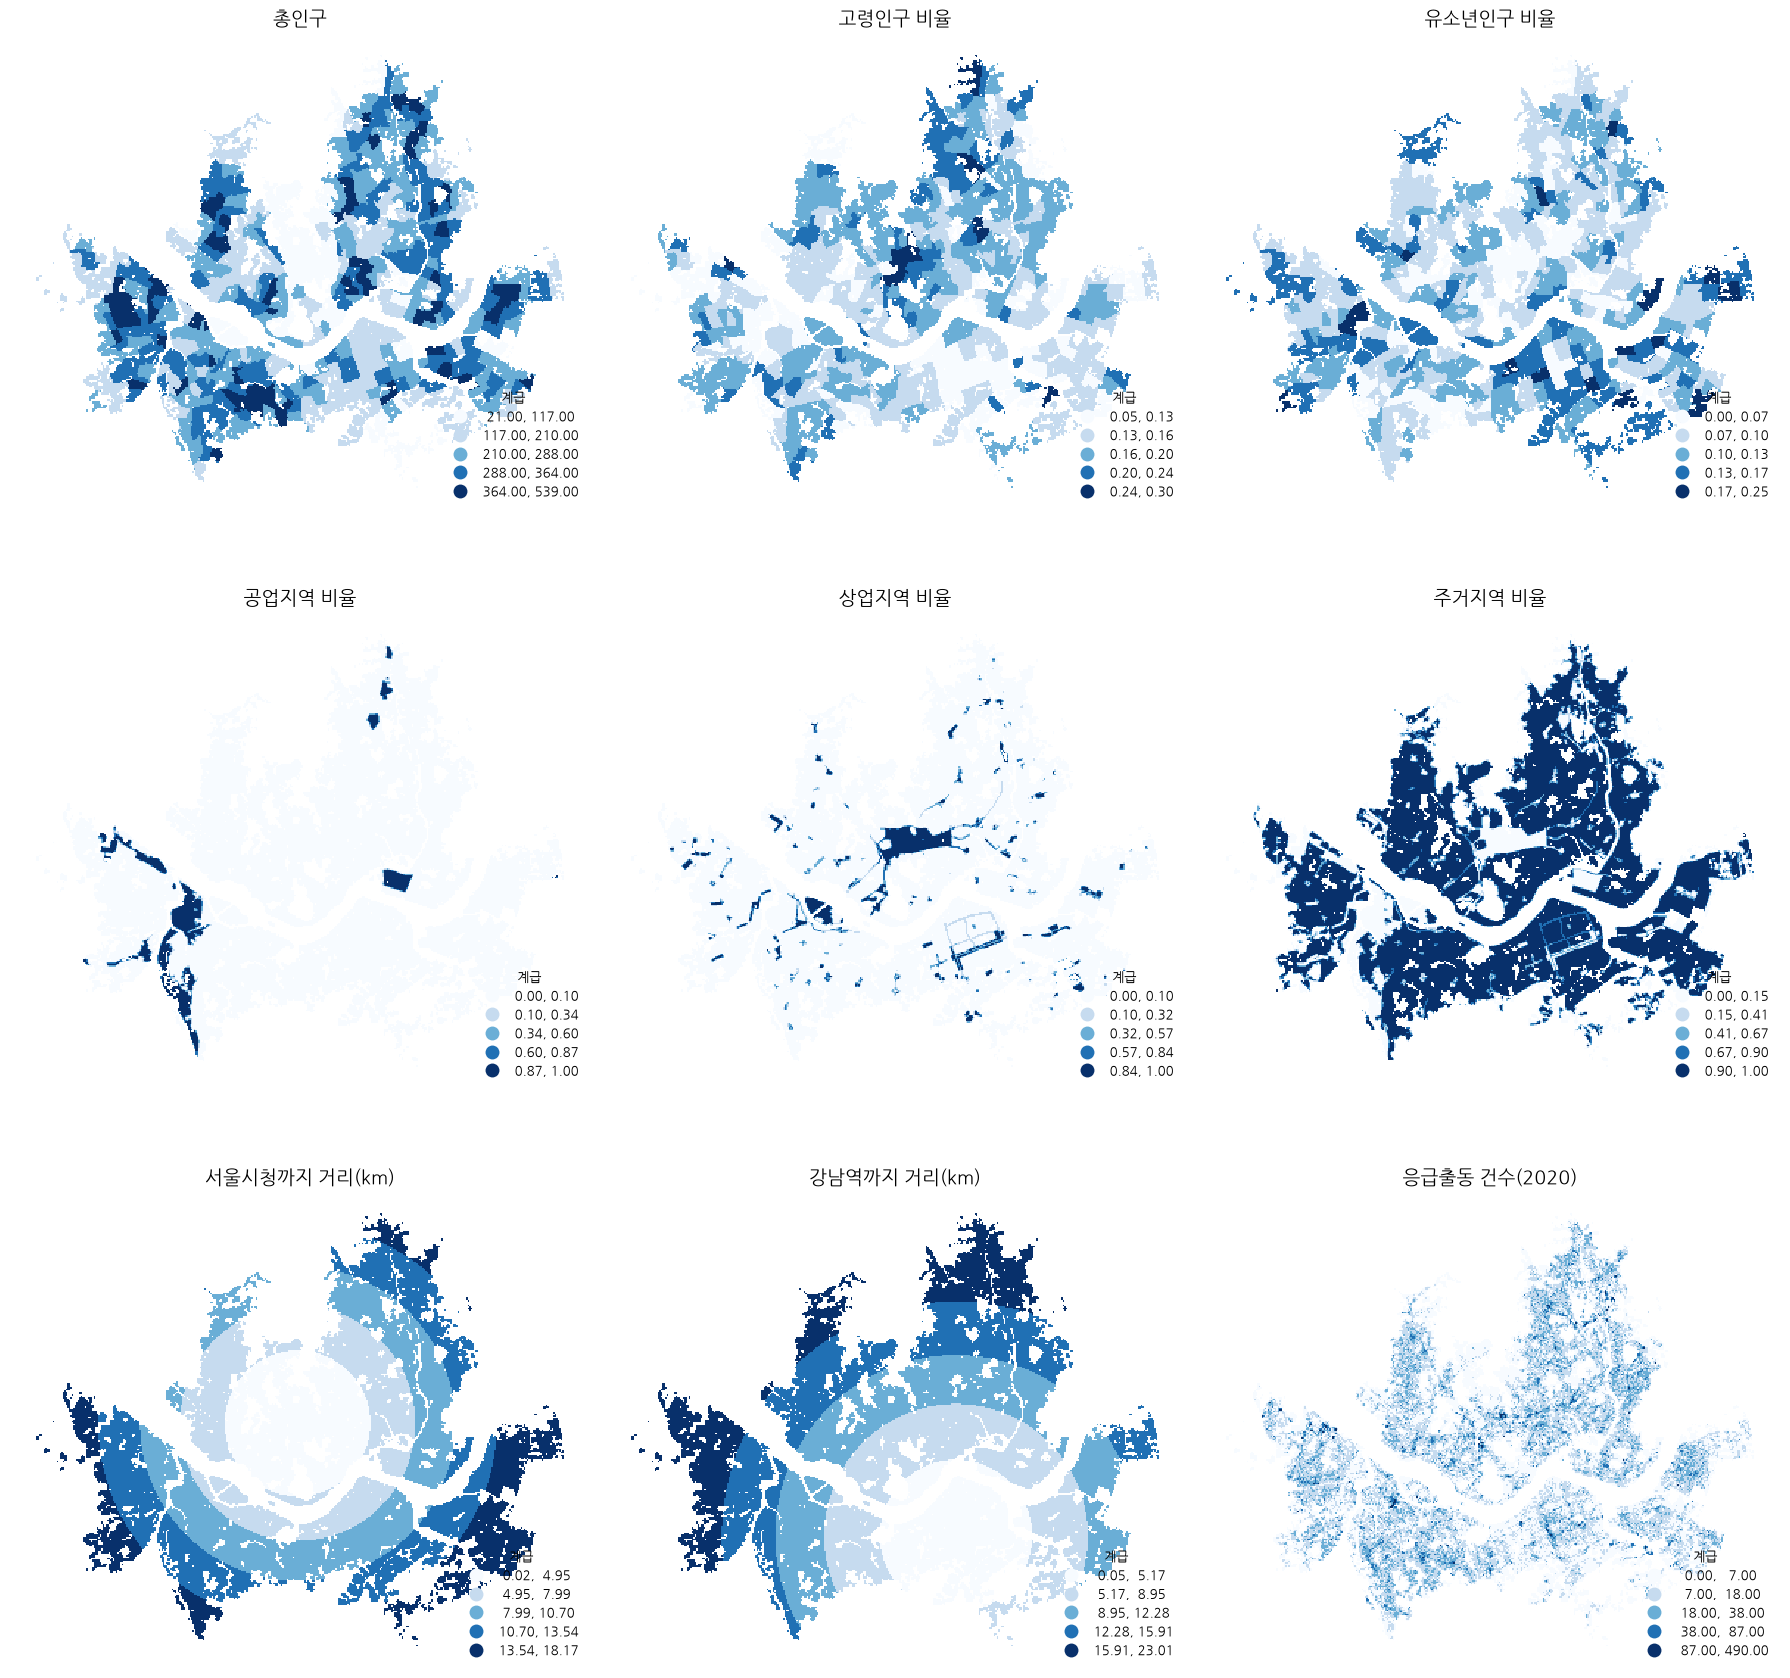

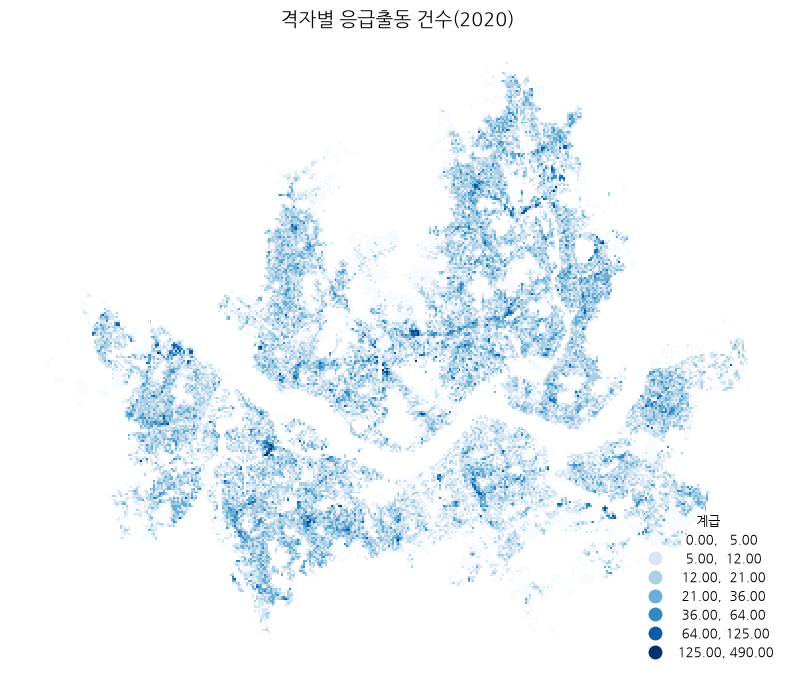

In [4]:
import koreanize_matplotlib  # 한글 폰트 설정 (venv에 설치되어 있음)
plt.rcParams['axes.unicode_minus'] = False  # NanumGothic의 마이너스 기호 경고 방지

# 시각화할 변수와 지도 제목
map_vars = {
    'total_pop': '총인구',
    'elder_ratio': '고령인구 비율',
    'youth_ratio': '유소년인구 비율',
    'industrial_ratio': '공업지역 비율',
    'commercial_ratio': '상업지역 비율',
    'residential_ratio': '주거지역 비율',
    'dist_seoul_city_hall': '서울시청까지 거리(km)',
    'dist_gangnam_station': '강남역까지 거리(km)',
    'emergency_no': '응급출동 건수(2020)',
}

plot_grid = pop_grid.copy()
plot_grid['dist_seoul_city_hall'] = plot_grid['dist_seoul_city_hall'] / 1000  # m → km
plot_grid['dist_gangnam_station'] = plot_grid['dist_gangnam_station'] / 1000


def plot_choropleth(gdf, col, title, ax, k=5, scheme='NaturalBreaks', cmap='Blues'):
    """격자 단위 단계구분도 한 장 그리기"""
    gdf.plot(column=col, ax=ax,
             scheme=scheme, k=k,               # mapclassify로 k개 계급 구분
             cmap=cmap,                        # 단일 색상(연→진) 순차 팔레트
             edgecolor='none',                 # 100m 격자라 경계선은 생략
             legend=True,
             legend_kwds={'loc': 'lower right', 'fmt': '{:,.2f}',
                          'fontsize': 9, 'title': '계급', 'title_fontsize': 9,
                          'frameon': False},
             missing_kwds={'color': 'lightgrey', 'label': '결측'})
    ax.set_title(title, fontsize=14)
    ax.set_axis_off()


# 1) 모든 변수를 3×3 지도로 한 번에 보기
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for ax, (col, title) in zip(axes.flat, map_vars.items()):
    plot_choropleth(plot_grid, col, title, ax)
plt.tight_layout()
plt.show()

# 2) 변수 하나만 크게 보기
fig, ax = plt.subplots(figsize=(10, 10))
plot_choropleth(plot_grid, 'emergency_no', '격자별 응급출동 건수(2020)', ax, k=7)
plt.show()


#### 각 속성의 분포, 이상치 확인

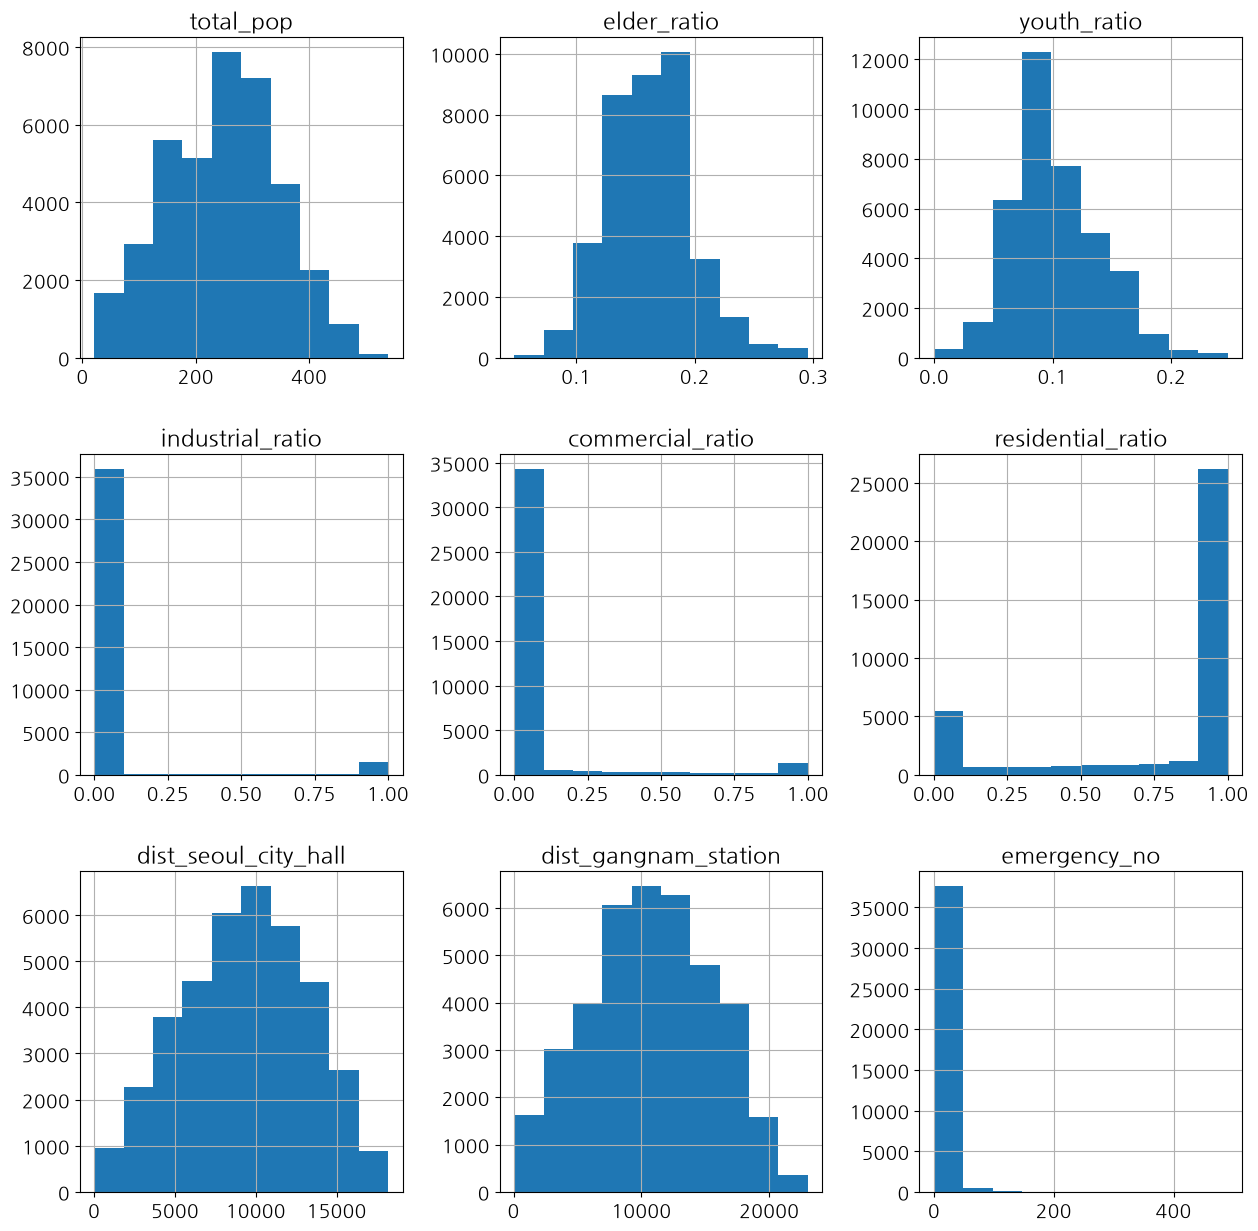

In [5]:
# plot할 때 default 속성을 미리 지정할 수 있습니다,
plt.rcParams['figure.figsize'] = (15,15)
plt.rcParams['font.size'] = 14
# 각 변수들의 histogram을 그려 분포를 살펴볼까요?
pop_grid.hist()
plt.show()

<Axes: >

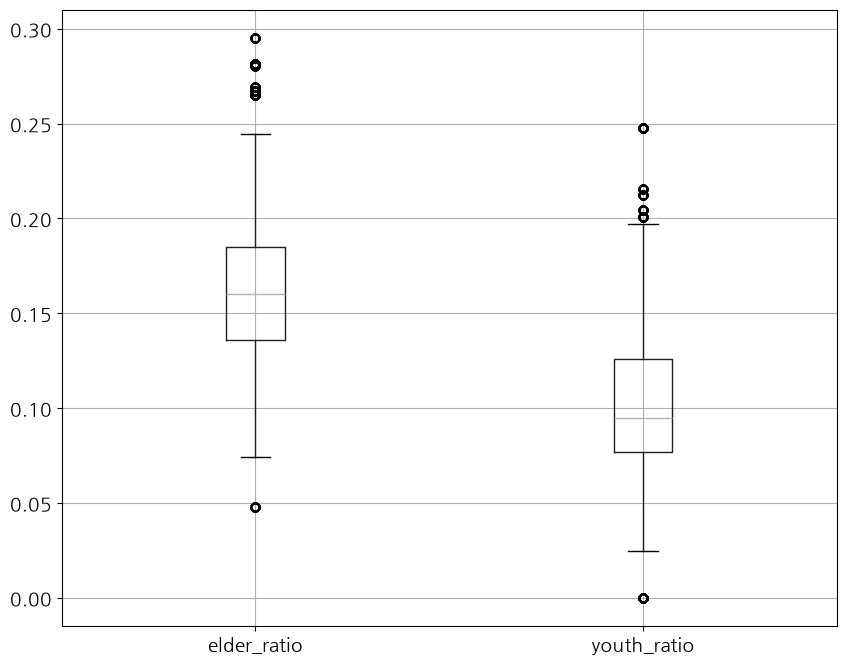

In [6]:
#컬럼별 이상치 확인
pop_grid.boxplot(column = ['elder_ratio','youth_ratio'], figsize = (10,8))

In [7]:
# 기술통계확인
pop_grid.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
total_pop,38094.0,247.24,99.49,21.00,164.00,258.00,319.00,539.00
elder_ratio,38094.0,0.16,0.04,0.05,0.14,0.16,0.18,0.30
youth_ratio,38094.0,0.10,0.04,0.00,0.08,0.09,0.13,0.25
industrial_ratio,38094.0,0.05,0.20,0.00,0.00,0.00,0.00,1.00
commercial_ratio,38094.0,0.06,0.21,0.00,0.00,0.00,0.00,1.00
residential_ratio,38094.0,0.78,0.37,0.00,0.66,1.00,1.00,1.00
dist_seoul_city_hall,38094.0,9327.67,3859.33,15.63,6586.40,9476.51,12227.24,18172.88
dist_gangnam_station,38094.0,10755.33,4792.79,47.33,7358.44,10801.51,14349.83,23008.05
emergency_no,38094.0,10.96,12.02,0.00,3.00,9.00,15.00,490.00


#### 속성간의 관계를 확인

In [8]:
# 상관관계 확인
correlation_matrix = pop_grid[['total_pop','elder_ratio','youth_ratio','industrial_ratio','commercial_ratio','residential_ratio','dist_seoul_city_hall','dist_gangnam_station','emergency_no']].corr()
correlation_matrix

,total_pop,elder_ratio,youth_ratio,industrial_ratio,commercial_ratio,residential_ratio,dist_seoul_city_hall,dist_gangnam_station,emergency_no
total_pop,1.000000,-0.136036,0.101593,-0.013437,-0.183518,0.284319,0.228269,0.162814,0.213660
elder_ratio,-0.136036,1.000000,-0.492498,-0.095115,0.048949,-0.002792,-0.138404,0.222851,0.095522
youth_ratio,0.101593,-0.492498,1.000000,-0.047477,-0.124317,-0.033732,0.299344,-0.003213,-0.205646
industrial_ratio,-0.013437,-0.095115,-0.047477,1.000000,-0.056922,-0.456965,0.088073,0.110188,-0.022638
commercial_ratio,-0.183518,0.048949,-0.124317,-0.056922,1.000000,-0.468214,-0.184941,-0.089812,0.180190
residential_ratio,0.284319,-0.002792,-0.033732,-0.456965,-0.468214,1.000000,-0.094799,-0.120006,0.116023
dist_seoul_city_hall,0.228269,-0.138404,0.299344,0.088073,-0.184941,-0.094799,1.000000,0.287496,-0.039430
dist_gangnam_station,0.162814,0.222851,-0.003213,0.110188,-0.089812,-0.120006,0.287496,1.000000,0.032740
emergency_no,0.213660,0.095522,-0.205646,-0.022638,0.180190,0.116023,-0.039430,0.032740,1.000000


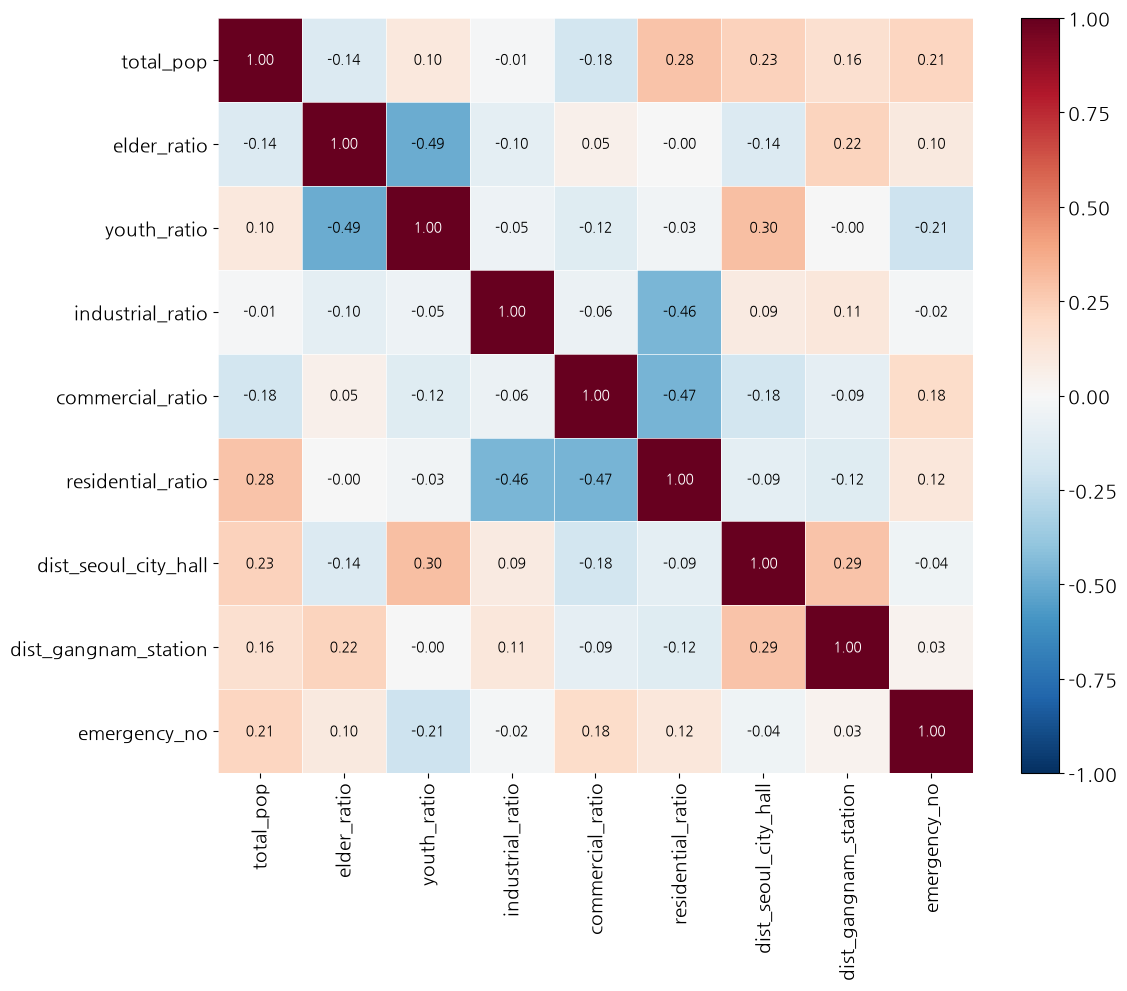

In [9]:
# matplotlib으로 그리는 pearson correlation matrix
labels = correlation_matrix.columns
values = correlation_matrix.values

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(values, cmap='RdBu_r', vmin=-1, vmax=1)  # 0을 중앙(흰색)에 고정
fig.colorbar(im, ax=ax)

# 축 눈금과 라벨
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticklabels(labels)

# 셀 경계선 (seaborn의 linewidth=0.5 역할)
ax.set_xticks(np.arange(len(labels) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(labels) + 1) - 0.5, minor=True)
ax.grid(which='minor', color='white', linewidth=0.5)
ax.tick_params(which='minor', length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

# 셀 안에 상관계수 표시 (seaborn의 annot=True 역할)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=10,
                color='white' if abs(v) > 0.6 else 'black')  # 진한 셀은 흰 글씨

plt.tight_layout()
plt.show()


## 8.3 선형회귀모형 (linear regression) 학습

가장 기본적인 머신러닝 모델이자, 가장 많이 쓰이는 통계모형인 선형회귀(Linear Regression) 모델을 학습시켜보겠습니다.\
Linear Regression은 X와 Y의 관계를 가장 간단한 선형방정식으로 나타내는 방법입니다.\
모델이 단순하고, 변수 간 통계적 유의성을 파악할 수 있다는 큰 장점이 있으나, 제약조건이 많고, 정확도가 높지 않은 단점이 있습니다.

<img src="https://miro.medium.com/max/1187/1*jOjxZ5g0RFJN0PqdR-G-Ug.png" width="400" height="400" />

<center>데이터를 가장 잘 설명하는 계수들(b0, b1....bn_)을 찾습니다</center>


먼저 독립변수(X)와 종속변수(Y)를 세팅하도록 하겠습니다

In [10]:
X = pop_grid[['total_pop', 'elder_ratio', 'youth_ratio', 'industrial_ratio',
       'commercial_ratio', 'residential_ratio','dist_seoul_city_hall', 'dist_gangnam_station']]
Y = pop_grid['emergency_no']

머신러닝 모델을 활용할 수 있는 대표적인 패키지로는 scikit-learn이 있습니다. 기본적인 회귀모형부터 다음시간에 배울 앙상블 모형, 간단한 신경망 모형 등 머신러닝 전반을 아우르는 모델들이 다수 포함되어 있습니다.

In [11]:
# Training set은 70%, Test set은 30%로 나누겠습니다.
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=100)

print(X_train.shape)
print(Y_train.shape)
print(X_test.shape)
print(Y_test.shape)

(26665, 8)
(26665,)
(11429, 8)
(11429,)


In [12]:
#linear regression model을 불러오고 linreg 변수에 선언합니다.
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()

# Training set 데이터를 모델에 학습시킵니다
linreg.fit(X_train,Y_train)

# 상수항과 계수, 회귀식을 출력합니다.
print('선형회귀모형의 상수항 : %f' % linreg.intercept_)
print('선형회귀모형의 계수')
print(linreg.coef_)

선형회귀모형의 상수항 : -2.065275
선형회귀모형의 계수
[ 2.50429370e-02  1.17818021e+01 -5.33824602e+01  6.42817898e+00
  1.90023432e+01  8.79064620e+00  1.30031458e-04  7.62394674e-05]


위 코드로 기본 선형회귀모형의 학습이 완료되었습니다.
출력된 계수에 따른 회귀식은 다음과 같습니다.

Y(격자 내 출동건수) ≈ -2.065275 + 0.025043 × 총인구 + 11.7818 × 고령층비율 - 53.3825 × 유소년층비율 + 6.4282 × 공업지역비율 + 19.0023 × 상업지역비율 + 8.7906 × 주거지역비율 + 0.00013003 × 서울시청까지 거리 + 0.00007624 × 강남역까지 거리

비율 변수는 0~1, 거리 변수는 m 단위입니다. 예를 들어 다른 조건이 같을 때 고령층비율이 1%p(0.01) 증가하면 예측 출동건수는 약 11.7818 × 0.01 = 0.1178건 증가합니다. 위 계수는 현재 저장된 학습 결과를 반올림한 값이며, 데이터를 변경하거나 다시 학습하면 달라질 수 있습니다.

In [13]:
# 참고 : statsmodel 패키지를 사용하여 통계적인 목적의 선형회귀분석을 진행할 수도 있습니다.
import statsmodels.api as sm
YXs = sm.add_constant(X)
model = sm.OLS(Y,YXs)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:           emergency_no   R-squared:                       0.171
Model:                            OLS   Adj. R-squared:                  0.170
Method:                 Least Squares   F-statistic:                     978.8
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:42:39   Log-Likelihood:            -1.4522e+05
No. Observations:               38094   AIC:                         2.905e+05
Df Residuals:                   38085   BIC:                         2.905e+05
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -1.9827 

## 8.4 선형회귀모형 학습 평가

학습된 선형 회귀 모형을 가지고, Test Set의 독립변수(X)를 넣어 도출된 값(Y')과 실제 값(Y)을 비교하여 정확도를 평가할 수 있습니다.\
평가 지표로는 MAE, MSE, RMSE, R_square 등이 있으며, 본 수업에는 R_square로 평가하도록 하겠습니다.\
R_square는 1 이하의 값을 가지며, 1에 가까울수록 정확도가 높습니다.

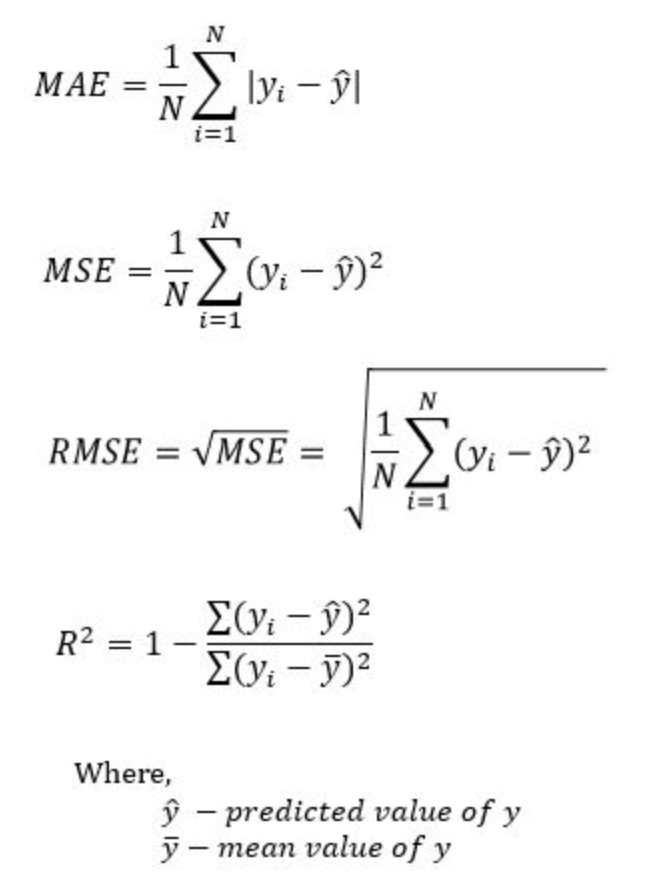

In [14]:
#predict 메서드로 독립변수를 넣으면 예측할 수 있습니다.
linreg.predict([[2000,0.2,0.1,0.3,0.2,0.5,5000,7000]])

c:\Users\leeja\Dropbox\0_Classes\5_스마트도시데이터분석\.venv2\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([56.34679235])

In [15]:
# training set과 Test set의 x 변수들로 예측 결과 값을 구합니다
Y_train_pred = linreg.predict(X_train)
Y_test_pred = linreg.predict(X_test)
Y_test_pred

array([ 6.59716514, 10.34418661, 13.25695424, ..., 16.28443575,
        8.71645543, 20.03979783], shape=(11429,))

In [16]:
from sklearn import metrics

# Training set의 예측 정확도
print('training R-square:', metrics.r2_score(Y_train, Y_train_pred))

# Test set의 예측 정확도 : Test set은 실제로 학습에 사용하지 않은 값들이므로, 이를 바탕으로 예측 정확도를 파악하는 것이 좋습니다.
print('test R-square:', metrics.r2_score(Y_test, Y_test_pred))

training R-square: 0.16692645800120365
test R-square: 0.17946131317893832


테스트셋의 R²는 약 0.1795입니다.
이는 테스트셋 실제 출동건수의 변동 중 약 17.95%를 이 모델이 설명한다는 뜻입니다. 예측값의 17.95%가 맞았다는 의미는 아닙니다.

## 8.5 Linear Regression 계열 모델 : Ridge, Lasso

다음은 Linear Regression의 개선된 모델인 Ridge, Lasso Regression에 대해 살펴보겠습니다. 두 모델은 변수가 너무 많아지는 경우, 모델이 학습데이터에 너무 최적화되어 오히려 예측 성능이 떨어지는 과적합(Overfitting) 위험을 개선하기 위하여 개발되었습니다. 기본적인 선형회귀모델은 변수 간의 다중공선성(multicollinearity)에 의해 성능이 하락하는데, 이 두 회귀모델은 이에 대해 대처할 수 있습니다.

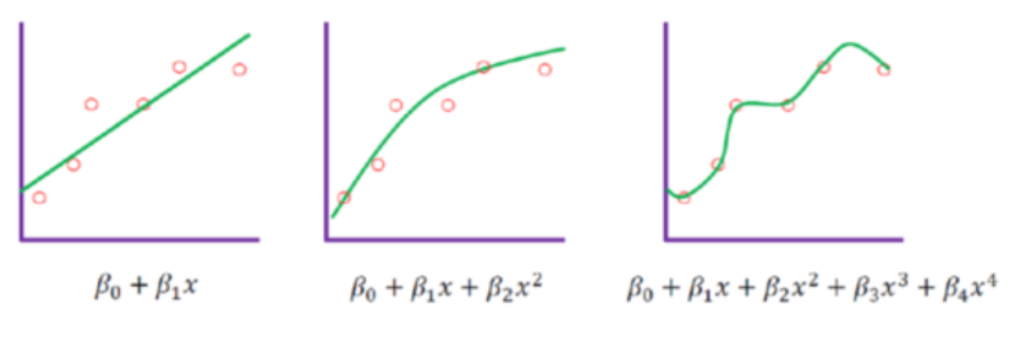

<center>모델이 복잡해지고, 들어가는 변수가 많아질수록 training set에 오히려 과적합되어 test set 정확도가 떨어지는 현상</center>

이 문제를 해결하기 위해 특정 독립변수의 계수가 커지는 것을 방지하는 penalty를 부여하게 됩니다. 이를 Regularization이라고 합니다.

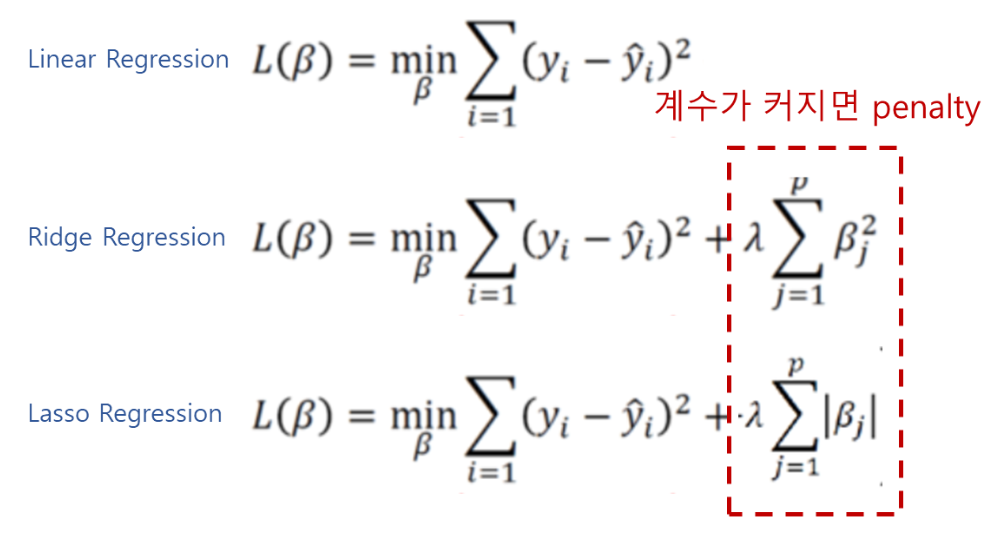

Ridge와 Lasso의 경우, penalty를 주는 방식에 있어서 차이가 존재합니다. Ridge는 전반적으로 계수들의 크기를 골고루 줄이는 역할, Lasso는 영향이 적은 변수의 계수를 0으로 만들어 변수를 선택하는 역할을 통해 penalty를 부여합니다.\
식을 보시면 λ값이 존재하는데, 이 값을 조절하여 penalty의 강도를 다르게 할 수 있고, 성능이 달라집니다. 이렇게 모델의 성능을 결정하는 입력값들을 hyperparameter라고 합니다.

In [17]:
# 변수의 단위가 계수와 규제 강도에 영향을 주므로 MinMaxScaler로 정규화
# 변수별 변환 공식: (X - 학습 데이터 최솟값) / (학습 데이터 최댓값 - 학습 데이터 최솟값)
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

# 학습 데이터에서 각 변수의 최솟값과 최댓값을 계산하고, 그 기준으로 학습 데이터를 변환
X_train2 = scaler.fit_transform(X_train)

# 새 기준을 계산하지 않고, 학습 데이터에서 기억한 각 변수의 최솟값과 최댓값으로 테스트 데이터를 변환
# 학습 데이터 범위를 벗어나는 테스트 값은 변환 후 0보다 작거나 1보다 클 수 있음
X_test2 = scaler.transform(X_test)

In [18]:
X_test

,total_pop,elder_ratio,youth_ratio,industrial_ratio,commercial_ratio,residential_ratio,dist_seoul_city_hall,dist_gangnam_station
7423,315.0,0.117460,0.180952,0.0,0.000000,0.677636,16114.669927,13082.882706
1713,145.0,0.089655,0.041379,0.0,0.000000,1.000000,8611.666170,267.997526
28201,270.0,0.170370,0.081481,0.0,0.000000,0.999702,10107.753986,10502.421914
2835,221.0,0.126697,0.135747,0.0,0.000000,1.000000,11113.758394,3803.798224
37453,162.0,0.179012,0.135802,0.0,0.170607,0.829393,6816.643723,2449.390914
...,...,...,...,...,...,...,...,...
19688,255.0,0.149020,0.074510,0.0,0.000000,1.000000,11528.459224,17138.102330
37648,246.0,0.117886,0.065041,0.0,0.000000,1.000000,10091.384475,6687.371641
29019,221.0,0.126697,0.135747,0.0,0.806760,0.193241,9922.554741,3275.420500
8745,349.0,0.123209,0.174785,0.0,0.000000,1.000000,8144.435314,929.952693


In [19]:
X_test2

array([[0.56756757, 0.28205128, 0.73104762, ..., 0.67763597, 0.8885231 ,
        0.56773261],
       [0.23938224, 0.16976127, 0.16717241, ..., 1.        , 0.47236657,
        0.00961052],
       [0.48069498, 0.4957265 , 0.32918519, ..., 0.99970162, 0.55534756,
        0.45534673],
       ...,
       [0.38610039, 0.31935259, 0.54841629, ..., 0.19324075, 0.54507543,
        0.14059173],
       [0.63320463, 0.3052678 , 0.70613181, ..., 1.        , 0.44645146,
        0.03844042],
       [0.45752896, 0.18336315, 0.1096124 , ..., 0.44441742, 0.44880371,
        0.28603426]], shape=(11429, 8))

In [20]:
from sklearn import set_config
set_config(display="text")

#Ridge, Lasso regression model을 불러오고 각 변수에 선언합니다.
from sklearn.linear_model import Ridge, Lasso
model1 = Ridge(alpha = 0.1)    # hyperparameter가 존재하며, 값들을 조절할 수 있습니다. λ에서 alpha로 이름만 바뀌었어요
model1.fit(X_train2,Y_train)   # Scaler를 적용한 Training set을 학습합니다.

model2 = Lasso(alpha = 0.1)
model2.fit(X_train2,Y_train)

Lasso(alpha=0.1)

In [21]:
# 상수항과 계수, 회귀식을 출력합니다.
print('선형회귀모형의 상수항 : %f' % linreg.intercept_)
print('선형회귀모형의 계수')
print(linreg.coef_)

print('Ridge모형의 상수항 : %f' % model1.intercept_)
print('Ridge모형의 계수')
print(model1.coef_)

print('Lasso모형의 상수항 : %f' % model2.intercept_)
print('Lasso모형의 계수')
print(model2.coef_)


선형회귀모형의 상수항 : -2.065275
선형회귀모형의 계수
[ 2.50429370e-02  1.17818021e+01 -5.33824602e+01  6.42817898e+00
  1.90023432e+01  8.79064620e+00  1.30031458e-04  7.62394674e-05]
Ridge모형의 상수항 : -0.960935
Ridge모형의 계수
[ 12.97113514   2.91754935 -13.21141148   6.42647986  18.99942225
   8.78931991   2.34339072   1.75042177]
Lasso모형의 상수항 : 5.666859
Lasso모형의 계수
[ 11.37012802   0.         -10.78986508   0.72701105  12.9113845
   5.01031681   0.           0.07963716]


**계수를 비교할 때 주의할 점**

선형회귀는 원래 단위의 `X_train`으로, Ridge와 Lasso는 0~1로 정규화한 `X_train2`로 학습했습니다. 그래서 계수의 단위가 다릅니다. 예를 들어 총인구 계수가 0.025에서 약 12.97로 커진 것은 규제 때문이 아니라 정규화 때문입니다. 정규화 후의 계수는 "해당 변수가 학습 데이터의 최솟값에서 최댓값까지 변할 때 예측값의 변화"를 뜻합니다.

alpha=0.1인 Ridge는 규제가 매우 약해서 사실상 정규화한 데이터의 선형회귀와 같은 결과를 냅니다. 반면 Lasso(alpha=0.1)는 고령층비율(`elder_ratio`)과 서울시청까지의 거리(`dist_seoul_city_hall`)의 계수를 정확히 0으로 만들어 변수를 선택했습니다.

In [22]:
import sklearn.metrics as metrics
from sklearn.metrics import mean_squared_error, r2_score

# training set과 Test set의 x 변수들로 예측 결과 값을 구합니다
Y_train_pred_ridge = model1.predict(X_train2)
Y_test_pred_ridge = model1.predict(X_test2)

Y_train_pred_lasso = model2.predict(X_train2)
Y_test_pred_lasso = model2.predict(X_test2)

#모델 성능을 비교하여 가장 좋은 성능을 내는 모델을 찾아봅시다.

# 기본 선형회귀모형 성능
print('Basic LR model')
print('training RMSE:', np.sqrt(metrics.mean_squared_error(Y_train, Y_train_pred)))
print('training R-square:', metrics.r2_score(Y_train, Y_train_pred))
print('test RMSE:', np.sqrt(metrics.mean_squared_error(Y_test, Y_test_pred)))
print('test R-square:', metrics.r2_score(Y_test, Y_test_pred))

# Ridge 모형 성능
print('Ridge model : alpha 0.1')
print('training RMSE:', np.sqrt(metrics.mean_squared_error(Y_train, Y_train_pred_ridge)))
print('training R-square:', metrics.r2_score(Y_train, Y_train_pred_ridge))
print('test RMSE:', np.sqrt(metrics.mean_squared_error(Y_test, Y_test_pred_ridge)))
print('test R-square:', metrics.r2_score(Y_test, Y_test_pred_ridge))

# Lasso 모형 성능
print('Lasso model : alpha 0.1')
print('training RMSE:', np.sqrt(metrics.mean_squared_error(Y_train, Y_train_pred_lasso)))
print('training R-square:', metrics.r2_score(Y_train, Y_train_pred_lasso))
print('test RMSE:', np.sqrt(metrics.mean_squared_error(Y_test, Y_test_pred_lasso)))
print('test R-square:', metrics.r2_score(Y_test, Y_test_pred_lasso))

Basic LR model
training RMSE: 11.115379515663241
training R-square: 0.16692645800120365
test RMSE: 10.548400226935124
test R-square: 0.17946131317893832
Ridge model : alpha 0.1
training RMSE: 11.115379536206618
training R-square: 0.16692645492184066
test RMSE: 10.548398236064694
test R-square: 0.1794616229104652
Lasso model : alpha 0.1
training RMSE: 11.225798849325118
training R-square: 0.15029286968187183
test RMSE: 10.658511179563115
test R-square: 0.1622412870840192


#### hyperparameter tuning

hyperparameter값을 조정하면서 최적의 성능을 찾아내는 과정을 hyperparameter tuning이라고 합니다. 이 과정을 일일히 매번 바꿔가면서 하면 힘들겠죠...\
따라서 for문을 통해 최적의 alpha값을 찾아내도록 하겠습니다.

In [23]:
def train_test_ridge(X_train, X_test, Y_train, Y_test, alpha_value):
    model = Ridge(alpha = alpha_value)   #alpha 값 다르게 하여 모델 만들기
    model.fit(X_train, Y_train)    #training set으로 모델 학습하기

    Y_pred_train = model.predict(X_train)    # training set의 X 값들로 모델 예측값 구하기
    Y_pred_test = model.predict(X_test)    # test set의 X 값들로 모델 예측값 구하기

    # training set의 rmse, r2구하기
    rmse_train = np.sqrt(metrics.mean_squared_error(Y_train, Y_pred_train))
    r2_train = metrics.r2_score(Y_train, Y_pred_train)

    # test set의 rmse, r2구하기
    rmse_test = np.sqrt(metrics.mean_squared_error(Y_test, Y_pred_test))
    r2_test = metrics.r2_score(Y_test, Y_pred_test)

    result={'rmse_train':rmse_train, 'rmse_test':rmse_test,
           'r2_train':r2_train, 'r2_test':r2_test}

    return result

In [24]:
alphas = [0,0.001,0.002,0.005,0.01,0.02,0.05,0.1,0.2,0.5,0.8,1, 2, 3, 4, 4.5, 5, 5.5, 6, 7, 8, 9, 10]    #alpha 값들 행렬로 만들기
rmse_train_score = []
rmse_test_score = []

for alpha in alphas:        #alpha 값들을 바꾸어 학습을 진행하고, 최종 모델의 성능 결과값을 얻습니다.
    result = train_test_ridge(X_train2, X_test2, Y_train, Y_test,alpha)
    rmse_test_score.append(result['rmse_test'])
    rmse_train_score.append(result['rmse_train'])
    print('Test results in %0.3f' % alpha)
    print(result['rmse_train'])
    print(result['rmse_test'])

min_value = min(rmse_test_score)     #가장 최적의 rmse 값을 가진 모델을 찾습니다.
min_index = rmse_test_score.index(min_value)


print('Minimum Test RMSE is:', min_value)
print('Best Alpha is:', alphas[min_index])

Test results in 0.000
11.115379515663241
10.548400226934826
Test results in 0.001
11.115379515665294
10.548400206806253
Test results in 0.002
11.11537951567146
10.548400186682123
Test results in 0.005
11.115379515714615
10.548400126336395
Test results in 0.010
11.115379515868733
10.548400025849041
Test results in 0.020
11.115379516485188
10.548399825207543
Test results in 0.050
11.115379520799914
10.548399225948334
Test results in 0.100
11.115379536206618
10.548398236064694
Test results in 0.200
11.115379597810202
10.548396289584545
Test results in 0.500
11.115380028584514
10.548390716056131
Test results in 0.800
11.115380827470812
10.548385540499122
Test results in 1.000
11.11538156404047
10.548382310655066
Test results in 2.000
11.115387682813752
10.54836879504386
Test results in 3.000
11.115397832757152
10.548359637895524
Test results in 4.000
11.11541197505609
10.54835479744566
Test results in 4.500
11.115420531320531
10.548353983050577
Test results in 5.000
11.115430071302152
10.5

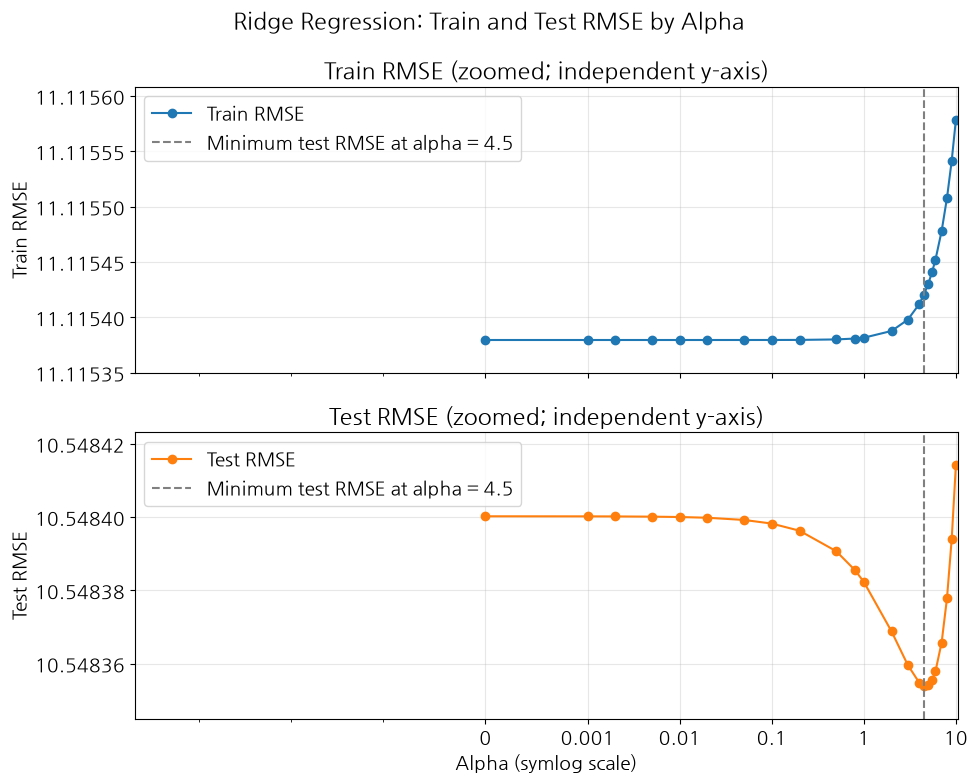

In [25]:
import matplotlib.pyplot as plt

# 작은 변화를 볼 수 있도록 각 패널의 y축을 독립적으로 자동 확대
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
best_alpha = alphas[min_index]

for ax, scores, label, color in zip(
    axes,
    [rmse_train_score, rmse_test_score],
    ['Train RMSE', 'Test RMSE'],
    ['tab:blue', 'tab:orange'],
):
    ax.plot(alphas, scores, marker='o', color=color, label=label)
    ax.axvline(best_alpha, color='gray', linestyle='--',
               label=f'Minimum test RMSE at alpha = {best_alpha}')
    ax.set_ylabel(label)
    ax.set_title(f'{label} (zoomed; independent y-axis)')
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    ax.margins(y=0.15)
    ax.grid(True, alpha=0.3)
    ax.legend()

# alpha=0을 포함하면서 작은 alpha도 구분할 수 있도록 symlog 축 사용
axes[-1].set_xscale('symlog', linthresh=0.001)
alpha_ticks = [a for a in [0, 0.001, 0.01, 0.1, 1, 10, 100]
               if min(alphas) <= a <= max(alphas)]
axes[-1].set_xticks(alpha_ticks)
axes[-1].set_xticklabels([str(a) for a in alpha_ticks])
axes[-1].set_xlabel('Alpha (symlog scale)')
fig.suptitle('Ridge Regression: Train and Test RMSE by Alpha')
plt.tight_layout()
plt.show()

# 단순 Train–Test 기반 alpha 탐색의 문제점

Ridge 회귀에서 여러 alpha로 모델을 학습한 뒤, **같은 테스트셋의 RMSE가 가장 낮은 alpha를 선택하면 테스트셋이 모델 선택에 사용됩니다.** 따라서 그 테스트 점수는 최종 모델의 독립적인 평가로 해석하기 어렵습니다.

## 1. 테스트셋에 우연히 잘 맞는 alpha를 선택할 수 있음

특정 alpha가 테스트셋에서 좋은 성능을 보이는 이유는 실제 예측력이 좋아서일 수도 있고, 그 테스트셋의 특성에 우연히 잘 맞아서일 수도 있습니다. 여러 후보를 비교하고 최솟값을 선택하면 이러한 우연까지 선택 결과에 반영될 수 있습니다.

예를 들어 아래는 설명을 위한 가상 결과입니다.

| Alpha | 테스트 RMSE |
|---:|---:|
| 0.1 | 10.550 |
| 1 | 10.548 |
| 5 | 10.549 |

이 테스트셋에서는 alpha=1이 가장 좋지만, 새로운 데이터에서도 같은 순서가 유지된다는 보장은 없습니다.

**회귀계수를 학습할 때 테스트 데이터를 넣지 않았더라도, alpha를 고르는 과정에서 테스트 정답을 활용했다는 점이 중요합니다.**

## 2. 선택된 모델의 성능이 낙관적으로 보일 수 있음

가장 낮은 테스트 RMSE를 기준으로 모델을 골랐으므로, 선택된 점수에는 그 테스트셋에 유리한 후보를 골랐다는 이점이 반영됩니다. 따라서 그 값을 새로운 데이터에서도 기대할 수 있는 성능으로 그대로 해석하기 어렵습니다.

```text
테스트셋으로 alpha 선택
        ↓
선택한 모델을 같은 테스트셋에서 평가
        ↓
모델 선택과 최종 평가가 같은 데이터에 의존
```

이러한 선택 편향이 모든 실행에서 반드시 같은 크기로 나타나는 것은 아닙니다. 그러나 평가 데이터가 선택 과정에 사용되었다는 구조적인 문제는 남습니다.

## 3. 한 번의 데이터 분할에 결과가 좌우됨

`train_test_split()`의 `random_state`를 바꾸면 학습·테스트 데이터의 구성도 달라집니다. 이에 따라 alpha별 RMSE와 최적 alpha가 달라질 수 있습니다.

특히 alpha별 RMSE 차이가 매우 작으면, 선택된 alpha가 모델의 뚜렷한 성능 차이보다 특정 분할의 특성을 반영할 가능성을 고려해야 합니다. 그래프를 확대해서 최저점이 선명하게 보이는 것과 실제 개선량이 큰 것은 별개의 문제입니다.

## 4. 학습·검증·테스트 데이터를 구분하는 방법

데이터의 역할을 다음처럼 나누면 alpha 선택과 최종 평가를 구분할 수 있습니다.

| 데이터 | 역할 |
|---|---|
| 학습셋 | 각 alpha에서 회귀계수와 절편 학습 |
| 검증셋 | alpha 후보의 성능을 비교하고 최적 후보 선택 |
| 테스트셋 | 선택이 끝난 모델의 최종 성능 평가 |

검증셋에서 alpha를 선택한 다음, 선택한 설정으로 학습셋과 검증셋을 합친 데이터에 모델을 다시 학습할 수 있습니다. 이후 별도로 보관한 테스트셋으로 평가합니다. 정규화 같은 전처리 기준도 각 학습 단계의 학습 데이터에서 계산해야 합니다.

**한 번의 분할로 튜닝하는 것 자체가 잘못은 아닙니다.** 튜닝에 사용한 데이터를 검증셋으로 취급하고, 최종 평가용 테스트셋을 별도로 확보하면 됩니다. 기존 테스트셋의 이름만 검증셋으로 바꾸는 것으로 별도의 최종 평가 데이터가 생기지는 않습니다.

# K-fold 교차검증으로 하이퍼파라미터 튜닝하기

## 1. 하이퍼파라미터는 무엇인가?

모델의 **파라미터**는 데이터로부터 학습하는 값입니다. 선형회귀의 회귀계수와 절편이 여기에 해당합니다. **하이퍼파라미터**는 학습 전에 정하는 설정값이며, Ridge 회귀에서는 규제 강도 `alpha`가 대표적입니다.

| 구분 | Ridge 회귀의 예 | 값을 결정하는 방법 |
|---|---|---|
| 파라미터 | 회귀계수, 절편 | 주어진 학습 데이터로 학습 |
| 하이퍼파라미터 | `alpha` | 여러 후보의 검증 성능을 비교해 선택 |

Ridge는 예측 오차와 회귀계수 크기에 대한 페널티를 함께 고려하여 학습합니다. `alpha`가 커지면 회귀계수를 줄이는 압력이 강해집니다. 너무 작은 값은 과적합을 충분히 줄이지 못할 수 있고, 너무 큰 값은 필요한 관계까지 약화시켜 과소적합을 일으킬 수 있습니다. 가장 적절한 값은 데이터에 따라 달라집니다.

## 2. 학습·검증·테스트 데이터의 역할

**학습 데이터는 회귀계수를 구하는 데, 검증 데이터는 alpha를 선택하는 데, 테스트 데이터는 선택이 끝난 모델을 평가하는 데 사용합니다.**

현재 노트북에서는 전체 데이터를 학습용 70%, 테스트용 30%로 먼저 분리합니다. 교차검증은 이 중 학습용 70% 안에서 수행합니다.

```text
전체 데이터
├─ 학습 데이터 70%
│  ├─ 5-fold 교차검증으로 alpha 후보 비교
│  └─ 선택한 alpha로 학습 데이터 70% 전체에 다시 학습
└─ 테스트 데이터 30%
   └─ 선택과 재학습이 끝난 모델의 최종 성능 평가
```

테스트 RMSE가 가장 낮아지는 alpha를 계속 찾으면 테스트 데이터도 모델 선택에 사용됩니다. 그렇게 얻은 테스트 점수는 처음 보는 데이터에 대한 독립적인 평가로 해석하기 어려워집니다.

## 3. 5-fold 교차검증의 진행 방법

학습 데이터를 크기가 거의 같은 다섯 묶음으로 나눕니다. 한 묶음을 검증용으로 남겨두고, 나머지 네 묶음으로 학습합니다. 검증용 묶음을 바꾸면서 총 다섯 번 반복합니다.

| 반복 | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 |
|---|---|---|---|---|---|
| 1 | 검증 | 학습 | 학습 | 학습 | 학습 |
| 2 | 학습 | 검증 | 학습 | 학습 | 학습 |
| 3 | 학습 | 학습 | 검증 | 학습 | 학습 |
| 4 | 학습 | 학습 | 학습 | 검증 | 학습 |
| 5 | 학습 | 학습 | 학습 | 학습 | 검증 |

한 번의 교차검증에서 각 관측치는 검증에 한 번, 학습에 네 번 참여합니다. **각 반복에서는 스케일러와 회귀모델을 새로 학습합니다.** 이전 반복에서 학습한 모델을 이어서 사용하는 방식이 아닙니다.

전체 데이터의 70%를 대상으로 5-fold를 수행하므로, 매 반복의 학습 부분은 전체 데이터의 약 56%(70% × 4/5), 검증 부분은 약 14%(70% × 1/5)입니다. 테스트용 30%는 여기에 참여하지 않습니다.

예를 들어 어떤 alpha의 다섯 검증 RMSE가 다음과 같다고 가정해 봅시다. 아래 값은 설명을 위한 가상 수치입니다.

```text
Fold별 검증 RMSE: 10.8, 11.2, 10.9, 11.5, 11.1
평균 검증 RMSE: (10.8 + 11.2 + 10.9 + 11.5 + 11.1) / 5 = 11.1
```

각 alpha에 대해 같은 다섯 분할로 평가한 뒤, **평균 검증 RMSE가 가장 낮은 후보**를 선택합니다. 이 값은 탐색한 후보 중의 최적값이며, 가능한 모든 실수 alpha 중의 최적값을 보장하지는 않습니다.

## 4. 정규화를 Pipeline에 넣는 이유

MinMaxScaler는 변수별 최솟값과 최댓값을 데이터에서 학습합니다. 따라서 교차검증을 시작하기 전에 학습 데이터 전체에 스케일러를 학습하면, 각 반복에서 검증용으로 남겨둬야 할 관측치도 정규화 기준에 영향을 줍니다.

각 fold에서는 다음 순서가 필요합니다.

1. 네 개 학습 fold에서만 스케일러의 기준을 계산합니다.
2. 그 기준으로 네 개 학습 fold를 변환합니다.
3. 같은 기준으로 나머지 한 개 검증 fold를 변환합니다.
4. 변환된 학습 데이터로 Ridge를 학습하고 검증 RMSE를 계산합니다.

`Pipeline`을 `GridSearchCV`에 전달하면 이 과정을 각 반복에서 수행할 수 있습니다. 따라서 **미리 정규화한 `X_train2`가 아니라 정규화 전의 `X_train`을 전달합니다.** 이 구성은 scikit-learn의 [전처리와 데이터 누출 관련 공식 설명](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)에 따른 것입니다.

```python
ridge_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('ridge', Ridge())
])
```



## 5. 실행 코드

노트북에서 `X`, `Y`를 만든 이후 실행할 수 있는 코드입니다. `X`는 정규화 전 독립변수, `Y`는 격자별 출동건수입니다.


In [26]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# 1. 최종 평가용 테스트 데이터를 먼저 분리
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=100
)

# 2. 정규화와 모델 학습을 하나의 과정으로 구성
ridge_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('ridge', Ridge())
])

# 3. 0.001부터 1000까지 로그 간격으로 25개 alpha 후보 생성
param_grid = {
    'ridge__alpha': np.logspace(-3, 3, 25)
}

# 4. 학습 데이터 안에서 사용할 5개 분할 설정
cv = KFold(n_splits=5, shuffle=True, random_state=100)

# 5. 모든 alpha를 같은 5개 분할로 평가
search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)
search.fit(X_train, Y_train)

# 6. 선택한 alpha로 전체 X_train에 재학습된 Pipeline 확인
best_ridge = search.best_estimator_
print('Best alpha:', search.best_params_['ridge__alpha'])
print('Mean validation RMSE:', -search.best_score_)

# 7. 최종 테스트 평가: Pipeline이 정규화도 함께 수행
# 기존 alpha=0.1 모델의 예측값과 구분하여 저장
Y_train_pred_ridge_cv = best_ridge.predict(X_train)
Y_test_pred_ridge_cv = best_ridge.predict(X_test)
print('Test RMSE:', np.sqrt(mean_squared_error(Y_test, Y_test_pred_ridge_cv)))
print('Test R²:', r2_score(Y_test, Y_test_pred_ridge_cv))

# 8. 후보별 결과 정리
cv_results = pd.DataFrame({
    'alpha': search.cv_results_['param_ridge__alpha'].astype(float),
    'mean_train_rmse': -search.cv_results_['mean_train_score'],
    'mean_validation_rmse': -search.cv_results_['mean_test_score'],
    'std_validation_rmse': search.cv_results_['std_test_score']
})
print(cv_results.sort_values('mean_validation_rmse').to_string(index=False))



Best alpha: 1.7782794100389228
Mean validation RMSE: 11.08995803908393
Test RMSE: 10.548371414207692
Test R²: 0.17946579574022392
      alpha  mean_train_rmse  mean_validation_rmse  std_validation_rmse
   1.778279        11.112853             11.089958             0.816895
   1.000000        11.112847             11.089961             0.816888
   3.162278        11.112875             11.089963             0.816907
   0.562341        11.112844             11.089964             0.816884
   0.316228        11.112844             11.089966             0.816882
   0.177828        11.112843             11.089968             0.816880
   0.100000        11.112843             11.089969             0.816880
   0.056234        11.112843             11.089969             0.816879
   0.031623        11.112843             11.089970             0.816879
   0.017783        11.112843             11.089970             0.816879
   0.010000        11.112843             11.089970             0.816879
   0.0

## 6. 코드의 주요 설정 읽기

| 설정 | 의미 |
|---|---|
| `ridge__alpha` | Pipeline의 `ridge` 단계에 있는 `alpha`를 탐색한다는 뜻. 단계 이름과 파라미터 이름을 밑줄 두 개로 연결 |
| `np.logspace(-3, 3, 25)` | 10⁻³부터 10³까지 일정한 배율 간격의 후보 25개 생성 |
| `n_splits=5` | 다섯 묶음으로 교차검증 |
| `shuffle=True` | 관측치 순서를 섞은 뒤 fold 구성 |
| `random_state=100` | 동일한 데이터와 실행 조건에서 같은 분할을 재현하기 위한 난수 설정 |
| `n_jobs=-1` | 사용 가능한 CPU 코어를 활용해 작업 병렬 처리 |
| `return_train_score=True` | 각 fold의 학습 점수도 결과에 포함 |
| `refit=True` | 후보 선택 후 최적 설정으로 전체 학습 데이터를 다시 학습 |

이 예제에서는 후보별 5회씩 **25 × 5 = 125회** 학습합니다. 최적 후보의 전체 학습 데이터 재학습 1회까지 포함하면 총 126회이며, 매 학습에는 해당 데이터에 대한 스케일러 학습도 포함됩니다. 테스트 평가에서는 추가 학습을 하지 않습니다. GridSearchCV의 탐색과 재학습 동작은 [공식 하이퍼파라미터 튜닝 문서](https://scikit-learn.org/stable/modules/grid_search.html)를 참고할 수 있습니다.

### 왜 음수 RMSE를 사용하는가?

GridSearchCV의 점수는 클수록 좋은 방향으로 정의됩니다. RMSE는 작을수록 좋으므로, `neg_root_mean_squared_error`는 RMSE에 마이너스를 붙입니다.

```text
RMSE 10 → 점수 -10
RMSE 12 → 점수 -12
-10이 -12보다 크므로 RMSE 10인 후보를 선택
```

따라서 `-search.best_score_`는 선택된 후보의 양수 평균 검증 RMSE입니다. `mean_train_score`, `mean_test_score`도 부호를 바꿉니다. 표준편차는 부호 반전에 따라 크기가 달라지지 않으므로 `std_test_score`에 마이너스를 붙이지 않습니다.

**`cv_results_`의 `test_score`는 여기서 각 fold의 검증 점수를 뜻합니다. 별도로 보관한 `X_test`, `Y_test`의 점수가 아닙니다.** 또한 평균 검증 RMSE는 fold별 RMSE의 산술평균이며, 모든 검증 예측을 모아서 한 번에 계산한 RMSE와는 다를 수 있습니다.


## 7. 결과와 그래프 해석

| 값 | 해석 |
|---|---|
| `mean_train_rmse` | 각 fold에서 학습에 사용한 데이터의 RMSE 평균 |
| `mean_validation_rmse` | 각 fold에서 학습에 사용하지 않은 검증 데이터의 RMSE 평균. alpha 선택 기준 |
| `std_validation_rmse` | fold별 검증 RMSE의 표준편차. 분할에 따른 점수 차이의 크기 |
| 최종 `Test RMSE` | 최적 alpha로 전체 학습 데이터에 재학습한 모델의 별도 테스트셋 성능 |

alpha를 x축에, 평균 검증 RMSE를 y축에 그리면 탐색한 후보 중의 최저점을 확인할 수 있습니다. 후보가 여러 자릿수에 걸쳐 있으므로 로그 x축이 적절합니다. 이 예제의 후보는 모두 양수입니다.

최솟값 주변이 평평하다면 다음처럼 최소 RMSE와의 차이를 그려 작은 변화를 살펴볼 수 있습니다.


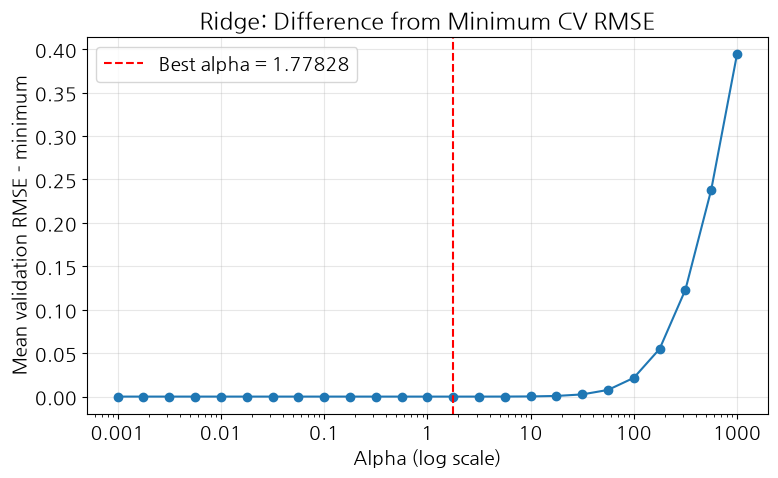

In [27]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams['axes.unicode_minus'] = False

data = cv_results.sort_values('alpha')
best_alpha = search.best_params_['ridge__alpha']
delta = data['mean_validation_rmse'] - data['mean_validation_rmse'].min()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(data['alpha'], delta, marker='o')
ax.axvline(best_alpha, color='red', linestyle='--',
           label=f'Best alpha = {best_alpha:g}')
ax.set_xscale('log')
# 로그 축 기본 눈금(10⁻³ 등)은 수식 글꼴로 그려져 한글 폰트에서 마이너스 글리프 경고가 나므로 일반 숫자로 표시
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:g}'))
ax.set_xlabel('Alpha (log scale)')
ax.set_ylabel('Mean validation RMSE - minimum')
ax.set_title('Ridge: Difference from Minimum CV RMSE')
ax.ticklabel_format(axis='y', style='plain', useOffset=False)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


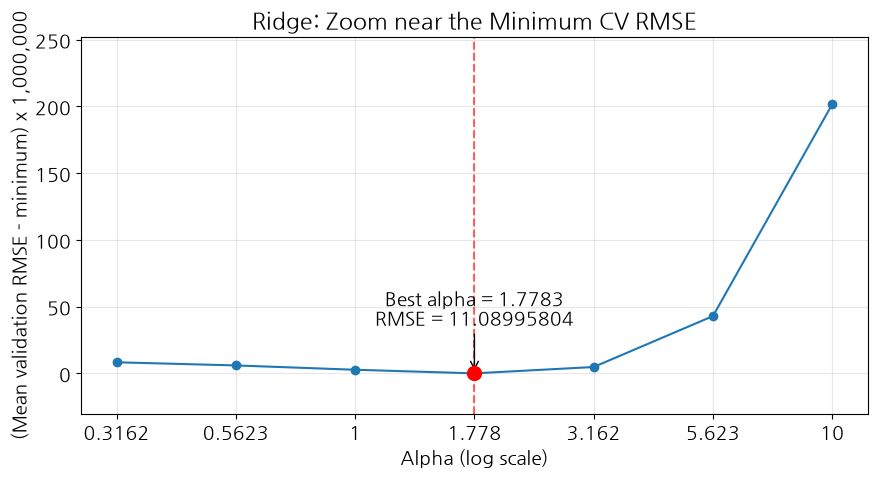

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# 마이너스 기호 폰트 경고 방지
plt.rcParams['axes.unicode_minus'] = False

data = cv_results.sort_values('alpha').reset_index(drop=True)
best_idx = data['mean_validation_rmse'].idxmin()
best_alpha = data.loc[best_idx, 'alpha']
best_rmse = data.loc[best_idx, 'mean_validation_rmse']

# 최적 후보 앞뒤 3개씩 선택
n_neighbors = 3
zoom = data.iloc[
    max(0, best_idx - n_neighbors):
    min(len(data), best_idx + n_neighbors + 1)
].copy()

# 작은 차이를 보기 쉽게 100만 배로 표시
zoom['delta'] = (
    zoom['mean_validation_rmse'] - best_rmse
) * 1_000_000

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(zoom['alpha'], zoom['delta'], marker='o')
ax.scatter(best_alpha, 0, color='red', s=100, zorder=5)
ax.axvline(best_alpha, color='red', linestyle='--', alpha=0.6)

ax.annotate(
    f'Best alpha = {best_alpha:.4f}\nRMSE = {best_rmse:.8f}',
    xy=(best_alpha, 0),
    xytext=(0, 35),
    textcoords='offset points',
    ha='center',
    arrowprops={'arrowstyle': '->'}
)

ax.set_xscale('log')
ax.set_xticks(zoom['alpha'])
ax.set_xticklabels([f'{a:.4g}' for a in zoom['alpha']])
ax.minorticks_off()

# 선택한 구간의 변화 폭에 맞춰 y축 확대
span = max(zoom['delta'].max(), 1e-6)
ax.set_ylim(-0.15 * span, 1.25 * span)

ax.set_xlabel('Alpha (log scale)')
ax.set_ylabel('(Mean validation RMSE - minimum) x 1,000,000')
ax.set_title('Ridge: Zoom near the Minimum CV RMSE')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

y=0이 탐색한 후보 중의 최저점입니다. 다만 그래프를 확대해서 최저점이 선명해져도 실제 개선량이 크다는 뜻은 아닙니다. RMSE 차이가 매우 작다면 데이터 분할을 조금 바꾸었을 때 최적 alpha가 달라질 수 있습니다.

## 8. 이 격자 데이터에 적용할 때의 주의점

현재 코드는 무작위로 섞은 K-fold를 사용합니다. 인접한 격자는 특성이 비슷할 수 있으므로, 무작위 분할에서는 가까운 격자가 학습과 검증에 함께 들어갈 수 있습니다. **새로운 지역에 대한 예측 성능**을 알고 싶다면 지역 그룹이나 공간 블록을 기준으로 분리하는 교차검증을 검토해야 합니다. 미래 연도 예측이 목적이라면 시간 순서를 보존하는 검증 설계가 필요합니다.

테스트 점수를 이미 여러 번 보면서 후보 범위나 분석 방법을 바꿨다면, 이후 교차검증을 적용해도 그 테스트셋이 새 데이터가 되는 것은 아닙니다. 엄밀한 최종 평가에는 추가로 보관한 데이터나 목적에 맞는 중첩 교차검증 설계를 사용할 수 있습니다.

최적 alpha가 탐색 범위의 맨 끝에서 선택되면 범위가 충분한지 확인하세요. 추가 탐색을 할 때도 기준은 학습 데이터 내부의 교차검증 점수로 유지합니다.


## 9. 최종 Ridge 모형의 계수 시각화

교차검증으로 고른 alpha로 학습 데이터 전체에 다시 학습한 `best_ridge`의 계수를 그려봅니다. Pipeline 안에서 MinMaxScaler로 정규화한 뒤 학습했으므로, 각 계수는 **해당 변수가 학습 데이터의 최솟값에서 최댓값까지 변할 때 예측 출동건수가 얼마나 변하는지**를 뜻합니다. 단위가 같아졌기 때문에 변수끼리 계수 크기를 비교할 수 있습니다.

In [29]:
# Pipeline에서 Ridge 단계를 꺼내 계수 확인
final_ridge = best_ridge.named_steps['ridge']
best_alpha = search.best_params_['ridge__alpha']

var_labels = {
    'total_pop': '총인구',
    'elder_ratio': '고령인구 비율',
    'youth_ratio': '유소년인구 비율',
    'industrial_ratio': '공업지역 비율',
    'commercial_ratio': '상업지역 비율',
    'residential_ratio': '주거지역 비율',
    'dist_seoul_city_hall': '서울시청까지 거리',
    'dist_gangnam_station': '강남역까지 거리',
}

# 최종 Ridge 모형의 절편과 계수 출력
print('최종 alpha:', best_alpha)
print('절편:', final_ridge.intercept_)

# 정규화 기준 계수를 원래 단위로 되돌리기: 계수 / (학습 데이터 최댓값 - 최솟값)
# 원래 단위 계수는 8.3절 기본 선형회귀(linreg)의 계수와 직접 비교할 수 있음
final_scaler = best_ridge.named_steps['scaler']
coef_table = pd.DataFrame({
    '변수': [var_labels.get(c, c) for c in X_train.columns],
    '계수(정규화 기준)': final_ridge.coef_,
    '계수(원래 단위)': final_ridge.coef_ / final_scaler.data_range_,
}, index=X_train.columns)
coef_table.sort_values('계수(정규화 기준)', ascending=False).round(6)

최종 alpha: 1.7782794100389228
절편: -0.9373478315410626


,변수,계수(정규화 기준),계수(원래 단위)
commercial_ratio,상업지역 비율,18.950548,18.950548
total_pop,총인구,12.952577,0.025005
residential_ratio,주거지역 비율,8.767140,8.767140
industrial_ratio,공업지역 비율,6.398070,6.398070
elder_ratio,고령인구 비율,2.920030,11.792430
dist_seoul_city_hall,서울시청까지 거리,2.326961,0.000129
dist_gangnam_station,강남역까지 거리,1.748896,0.000076
youth_ratio,유소년인구 비율,-13.176809,-53.234307


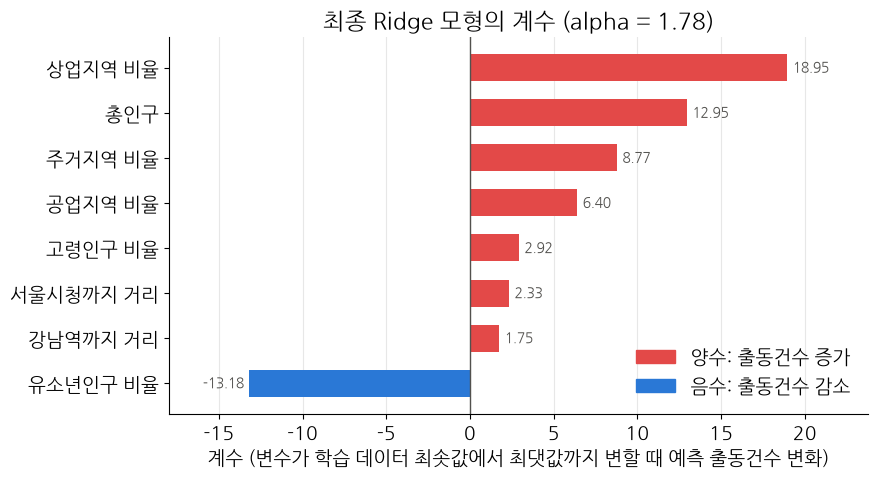

절편: -0.9373478315410626


In [30]:
from matplotlib.patches import Patch

# 계수 출력 셀에서 만든 final_ridge, best_alpha, var_labels를 사용
# 1. 변수 이름과 계수를 묶어 크기 순으로 정렬 (가장 큰 양수가 맨 위)
coef = pd.Series(final_ridge.coef_, index=X_train.columns).sort_values()
labels = [var_labels.get(c, c) for c in coef.index]

# 2. 부호에 따라 색 구분: 양수(출동건수 증가)는 빨강, 음수(감소)는 파랑
pos_color, neg_color, ink = '#e34948', '#2a78d6', '#52514e'
colors = [pos_color if v > 0 else neg_color for v in coef]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(labels, coef.values, color=colors, height=0.6)
ax.axvline(0, color=ink, linewidth=1)

# 3. 막대 끝에 계수 값 표시
for bar, v in zip(bars, coef.values):
    ax.annotate(f'{v:.2f}', xy=(v, bar.get_y() + bar.get_height() / 2),
                xytext=(4 if v > 0 else -4, 0), textcoords='offset points',
                ha='left' if v > 0 else 'right', va='center',
                fontsize=10, color=ink)

ax.margins(x=0.15)  # 값 라벨이 잘리지 않도록 좌우 여백 확보
ax.set_xlabel('계수 (변수가 학습 데이터 최솟값에서 최댓값까지 변할 때 예측 출동건수 변화)')
ax.set_title(f'최종 Ridge 모형의 계수 (alpha = {best_alpha:.3g})')
ax.legend(handles=[Patch(color=pos_color, label='양수: 출동건수 증가'),
                   Patch(color=neg_color, label='음수: 출동건수 감소')],
          loc='lower right', frameon=False)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

print('절편:', final_ridge.intercept_)